# AA3 · Parcial II · Cuaderno 3: Transformers
**Alumno:** Edgar Ivan Galvez Ortega
**Datos:** temática opcional · mesa de ayuda de una universidad ficticia: 180 pares sintéticos (mensaje → ticket JSON) y 25 de prueba escritos aparte
**Opción:** LoRA

Ajuste con **LoRA** de `Qwen/Qwen2.5-0.5B-Instruct` para convertir el mensaje de un estudiante en un **ticket JSON** con cinco campos (`nombre`, `id_alumno`, `area`, `asunto`, `urgente`). Se compara con el mismo modelo sin ajustar, primero con un *prompt* corto y luego con un *prompt* con reglas. Sale del ejercicio final de la Práctica 6.

> Todo es ficticio: la universidad, los mensajes, los nombres y las matrículas.

## 1. Datos
### 1.1 Entorno
Instala lo que falte (sobre todo `peft`, la librería de Hugging Face para LoRA) y revisa la GPU.

In [1]:
import os
import sys
import importlib.util
import subprocess

EN_COLAB = importlib.util.find_spec("google.colab") is not None
paquetes = {"transformers": "transformers", "peft": "peft", "accelerate": "accelerate", "torch": "torch",
            "pandas": "pandas", "matplotlib": "matplotlib"}
faltantes = [pip for mod, pip in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print(f"Instalando paquetes faltantes: {faltantes}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
else:
    print("Todas las dependencias ya están instaladas.")

os.environ["USE_TF"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import torch
import transformers
import peft

print("--- Auditoría de Entorno ---")
print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local / servidor'} · Python {sys.version.split()[0]}")
print(f"PyTorch {torch.__version__} · transformers {transformers.__version__} · peft {peft.__version__}")
GPU = torch.cuda.is_available()
print(f"¿GPU disponible?: {GPU}" + (f" ({torch.cuda.get_device_name(0)}, "
      f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)" if GPU else ""))

Todas las dependencias ya están instaladas.


c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Auditoría de Entorno ---
Entorno: Local / servidor · Python 3.13.0
PyTorch 2.6.0+cu124 · transformers 5.17.0 · peft 0.21.2
¿GPU disponible?: True (NVIDIA GeForce RTX 4070 SUPER, 12.0 GB)


In [2]:
import gc
import json
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
transformers.set_seed(SEED)
DISPOSITIVO = "cuda" if GPU else "cpu"
BF16 = GPU and torch.cuda.is_bf16_supported()                     # RTX 30xx/40xx: bfloat16
FP16 = GPU and not BF16 and torch.cuda.get_device_capability()[0] >= 7   # T4: float16 con precisión mixta
DTYPE_GENERAR = torch.bfloat16 if BF16 else (torch.float16 if GPU else torch.float32)
DTYPE_ENTRENAR = torch.bfloat16 if BF16 else (torch.float16 if FP16 else torch.float32)
DIR_MODELOS = os.path.join("modelos", "C3")
os.makedirs(DIR_MODELOS, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

def liberar_gpu():
    gc.collect()
    if GPU:
        torch.cuda.empty_cache()

print(f"Generar en {DTYPE_GENERAR} · entrenar en {DTYPE_ENTRENAR} (bf16: {BF16}, fp16: {FP16})")

Generar en torch.bfloat16 · entrenar en torch.bfloat16 (bf16: True, fp16: False)


### 1.2 La tarea y los datos
**Tarea, con salida verificable:** la mesa de ayuda recibe un mensaje y debe abrir un **ticket en JSON**:
```json
{"nombre": "Ana López", "id_alumno": "A1023", "area": "finanzas", "asunto": "adeudo de colegiatura", "urgente": false}
```
- `area` es una de cuatro: `escolares`, `finanzas`, `sistemas` o `seguridad`.
- `id_alumno` va normalizado como «A» + 4 dígitos (aunque el alumno escriba `a 6 6 0 3` o `A-3092`); `null` si no la dice.
- `urgente` es `true` solo si alguien está en peligro (desmayo, herida, gas, humo). Un robo o una credencial perdida son de `seguridad` pero **no** urgentes.

**Datos:**
- **180 pares sintéticos** (150 de entrenamiento y 30 de validación). Se generan con plantillas: 19 situaciones, 24 nombres, matrículas escritas de cinco formas, nombres que se corrigen («Laura Torres, perdón, Laura Martínez») y ruido (minúsculas, sin acentos). El mínimo que pide el PDF es 100.
- **25 mensajes de prueba escritos a mano y aparte**, con **otro estilo**: faltas de ortografía, abreviaturas («biblio», «q», «uni»), **nombres que el modelo nunca vio**, situaciones dichas con otras palabras («me hicieron doble cargo», «se abrió la mano con un vidrio») y mensajes con **dos temas** («ya pagué la reinscripción pero sigo sin poder inscribir materias»). El mínimo que pide el PDF es 20. **No salen del generador.**

In [3]:
# Pares (mensaje de un estudiante → ticket JSON) para la mesa de ayuda de la universidad ficticia «Universidad del Valle Alto».
# - Entrenamiento y validación: plantillas + ruido, con nombres y frases "de entrenamiento" (generar() es determinista).
# - Prueba: 25 mensajes escritos A MANO y APARTE, con otro estilo (faltas, abreviaturas, nombres corregidos,
#   matrículas dichas de otra forma, mensajes con dos temas) y con nombres y frases que el modelo NO vio.
# Todo es ficticio: no hay datos de ninguna persona real.
import random

AREAS = ["escolares", "finanzas", "sistemas", "seguridad"]
CAMPOS = ["nombre", "id_alumno", "area", "asunto", "urgente"]

NOMBRES_TRAIN = ["Ana López", "Luis Hernández", "María García", "Jorge Ramírez", "Carmen Torres", "Miguel Flores",
                 "Laura Martínez", "José Sánchez", "Daniela Cruz", "Alejandro Morales", "Patricia Reyes", "Ricardo Jiménez",
                 "Gabriela Ortiz", "Fernando Castillo", "Lucía Vargas", "Héctor Romero", "Mónica Díaz", "Sergio Mendoza",
                 "Adriana Aguilar", "Raúl Medina", "Carlos Navarro", "Elena Ríos", "Pablo Guerrero", "Teresa Molina"]

# (frase en el mensaje, área, asunto normalizado, palabras clave para calificar el asunto, urgente)
SITUACIONES = [
    ("no me deja inscribir las materias de este semestre", "escolares", "problema con inscripción de materias", ["inscrip", "materia"], False),
    ("necesito una constancia de estudios", "escolares", "constancia de estudios", ["constancia"], False),
    ("quiero dar de baja una materia", "escolares", "baja de materia", ["baja"], False),
    ("tengo choque de horario entre dos materias", "escolares", "choque de horario", ["horario", "choque"], False),
    ("necesito mi kardex", "escolares", "solicitud de kardex", ["kardex", "historial"], False),
    ("ya pagué la colegiatura y me sigue saliendo adeudo", "finanzas", "adeudo de colegiatura", ["adeudo"], False),
    ("me cobraron dos veces la mensualidad", "finanzas", "cobro duplicado", ["dos veces", "duplicad", "doble"], False),
    ("no me aplicaron el descuento de mi beca", "finanzas", "descuento de beca no aplicado", ["beca"], False),
    ("necesito la factura de la colegiatura", "finanzas", "factura de colegiatura", ["factura"], False),
    ("no puedo entrar a Moodle, dice que mi contraseña está mal", "sistemas", "acceso a Moodle", ["moodle", "contrasena"], False),
    ("no me llega el código de verificación", "sistemas", "código de verificación", ["codigo", "verificacion"], False),
    ("el wifi del campus no funciona en la biblioteca", "sistemas", "falla de wifi", ["wifi", "internet"], False),
    ("mi correo institucional está bloqueado", "sistemas", "correo institucional bloqueado", ["correo"], False),
    ("un compañero se desmayó en el laboratorio", "seguridad", "persona desmayada", ["desmay", "inconsciente"], True),
    ("hay olor a gas en el edificio de química", "seguridad", "posible fuga de gas", ["gas"], True),
    ("hay humo saliendo de un salón", "seguridad", "humo en un salón", ["humo", "incendio", "fuego"], True),
    ("alguien se cortó y está sangrando mucho", "seguridad", "persona herida sangrando", ["sangr", "herid", "cort"], True),
    ("perdí mi credencial en la cafetería", "seguridad", "credencial perdida", ["credencial"], False),
    ("se robaron mi bicicleta del estacionamiento", "seguridad", "robo de bicicleta", ["robo", "bici"], False),
]

SALUDOS = ["", "", "Hola, ", "Buenas tardes, ", "Buen día, ", "Qué tal, "]
CIERRES = ["", "", " Gracias.", " Por favor.", " Saludos.", " Quedo atento."]


def _sin_acentos(t):
    return t.translate(str.maketrans("áéíóúÁÉÍÓÚ", "aeiouAEIOU"))


def _formato_id(numero, rng):
    # Cómo escribe el alumno su matrícula; en el ticket siempre va normalizada como A + 4 dígitos
    d = str(numero)
    return rng.choice([f"A{d}", f"A{d}", f"a{d}", f"A-{d}", "A " + " ".join(d)])


def _mensaje(nombre, id_txt, frase, rng):
    con_id = [
        f"soy {nombre}, mi matrícula es {id_txt}. {frase[0].upper() + frase[1:]}.",
        f"{frase[0].upper() + frase[1:]}. Mi nombre es {nombre} ({id_txt}).",
        f"{nombre}, matrícula {id_txt}: {frase}.",
        f"me llamo {nombre} y mi matrícula es {id_txt}, {frase}.",
        f"{frase[0].upper() + frase[1:]}, soy {nombre} con matrícula {id_txt}.",
    ]
    sin_id = [
        f"soy {nombre}, {frase}.",
        f"{frase[0].upper() + frase[1:]}. Atentamente, {nombre}.",
        f"me llamo {nombre}, {frase}, no me sé mi matrícula.",
    ]
    return rng.choice(con_id if id_txt else sin_id)


def generar(n=180, semilla=42):
    rng = random.Random(semilla)
    pares, vistos = [], set()
    while len(pares) < n:
        frase, area, asunto, claves, urgente = rng.choice(SITUACIONES)
        nombre = rng.choice(NOMBRES_TRAIN)
        dicho = nombre
        if rng.random() < 0.12:                    # se corrige el nombre: vale la versión final
            otro = rng.choice([x for x in NOMBRES_TRAIN if x != nombre])
            dicho = f"{otro.split()[0]} {otro.split()[1]}, perdón, {nombre}"
        numero = rng.randint(1000, 9999)
        id_txt = _formato_id(numero, rng) if rng.random() > 0.15 else None
        saludo, cuerpo = rng.choice(SALUDOS), _mensaje(dicho, id_txt, frase, rng)
        cuerpo = (cuerpo[0].lower() if saludo else cuerpo[0].upper()) + cuerpo[1:]
        texto = saludo + cuerpo + rng.choice(CIERRES)
        if rng.random() < 0.3:
            texto = texto.lower()
        if rng.random() < 0.3:
            texto = _sin_acentos(texto)
        if texto in vistos:
            continue
        vistos.add(texto)
        ticket = {"nombre": nombre, "id_alumno": f"A{numero}" if id_txt else None, "area": area,
                  "asunto": asunto, "urgente": urgente}
        pares.append((texto, ticket, claves))
    return pares


def _t(nombre, id_alumno, area, asunto, urgente):
    return {"nombre": nombre, "id_alumno": id_alumno, "area": area, "asunto": asunto, "urgente": urgente}

# Prueba escrita aparte (25): otro estilo y otros nombres. (mensaje, ticket correcto, palabras clave del asunto)
PRUEBA = [
    ("hola soy Valeria Quintanilla matricula a4417, ya pague la colegiatura desde el viernes y el portal dice q debo",
     _t("Valeria Quintanilla", "A4417", "finanzas", "adeudo de colegiatura", False), ["adeudo", "debo", "pago"]),
    ("Me llamo Rodrigo Esparza, A-3092. el moodle no me reconoce la clave y mañana entrego tarea",
     _t("Rodrigo Esparza", "A3092", "sistemas", "acceso a Moodle", False), ["moodle", "clave", "contrasena", "acceso"]),
    ("URGENTE mi compañero se desmayo en el lab de fisica y no responde, soy Itzel Carrasco",
     _t("Itzel Carrasco", None, "seguridad", "persona desmayada", True), ["desmay", "inconsciente", "no responde"]),
    ("buenas, Damián Olvera (A5520). me hicieron doble cargo de la mensualidad de octubre en la tarjeta",
     _t("Damián Olvera", "A5520", "finanzas", "cobro duplicado", False), ["doble", "duplicad", "dos veces", "cargo"]),
    ("Soy Ximena Barragán, matrícula A1876. Ocupo un papel que diga que estudio aqui para mi visa",
     _t("Ximena Barragán", "A1876", "escolares", "constancia de estudios", False), ["constancia", "comprobante", "papel"]),
    ("hay un olor muy fuerte a gas en el edificio C!!! soy el alumno Emiliano Robles A2045",
     _t("Emiliano Robles", "A2045", "seguridad", "posible fuga de gas", True), ["gas"]),
    ("Hola, me llamo Renata Zavala, perdón, Renata Saldívar, matrícula A7731, no puedo meter Estadística en mi horario",
     _t("Renata Saldívar", "A7731", "escolares", "problema con inscripción de materias", False), ["inscrip", "materia", "estadistica"]),
    ("perdi mi credencial en las canchas ayer, Mateo Gallardo a 6 6 0 3",
     _t("Mateo Gallardo", "A6603", "seguridad", "credencial perdida", False), ["credencial"]),
    ("soy Fernanda Ochoa A8890 y la beca de excelencia no se ve en mi estado de cuenta",
     _t("Fernanda Ochoa", "A8890", "finanzas", "descuento de beca no aplicado", False), ["beca"]),
    ("Nunca recibo el codigo para entrar al portal. Atte. Sebastián Ibarra, A3318",
     _t("Sebastián Ibarra", "A3318", "sistemas", "código de verificación", False), ["codigo", "verificacion"]),
    ("esta saliendo humo negro de un salon del edificio de ingenieria, me llamo Andrea Villaseñor",
     _t("Andrea Villaseñor", None, "seguridad", "humo en un salón", True), ["humo", "incendio", "fuego"]),
    ("Buen día, Leonardo Cervantes, A0927. se me empalman Redes y Bases de Datos los martes",
     _t("Leonardo Cervantes", "A0927", "escolares", "choque de horario", False), ["horario", "choque", "empalm"]),
    ("me pueden facturar lo del semestre? Paulina Arreola, matricula A5064",
     _t("Paulina Arreola", "A5064", "finanzas", "factura de colegiatura", False), ["factura"]),
    ("soy Tomás Benavides (A2210) un chavo se abrio la mano con un vidrio y no para de sangrar en la cafeteria",
     _t("Tomás Benavides", "A2210", "seguridad", "persona herida sangrando", True), ["sangr", "herid", "cort", "mano"]),
    ("Regina Montoya A9183, no hay internet en la biblio desde la mañana",
     _t("Regina Montoya", "A9183", "sistemas", "falla de wifi", False), ["wifi", "internet", "red"]),
    ("hola me quiero salir de calculo, me llamo Gael Fuentes y mi matricula es A4401",
     _t("Gael Fuentes", "A4401", "escolares", "baja de materia", False), ["baja", "salir", "calculo"]),
    ("ya no esta mi bici donde la deje en el estacionamiento, soy Camila Treviño, A6127",
     _t("Camila Treviño", "A6127", "seguridad", "robo de bicicleta", False), ["robo", "bici"]),
    ("Diego Salazar aqui, A3755: me suspendieron la cuenta de correo de la uni",
     _t("Diego Salazar", "A3755", "sistemas", "correo institucional bloqueado", False), ["correo", "cuenta"]),
    ("me pueden dar mi historial de calificaciones? soy Mariana Pacheco, no me acuerdo de mi matricula",
     _t("Mariana Pacheco", None, "escolares", "solicitud de kardex", False), ["kardex", "historial", "calificaciones"]),
    ("Soy Iker Domínguez A1192, ya pagué la reinscripción pero sigo sin poder inscribir materias",
     _t("Iker Domínguez", "A1192", "escolares", "problema con inscripción de materias", False), ["inscrib", "inscrip", "materia"]),
    ("se cayo una maestra por las escaleras y no se puede levantar, edificio D. Natalia Rangel A8042",
     _t("Natalia Rangel", "A8042", "seguridad", "persona lesionada por caída", True), ["cay", "caida", "herid", "lesion", "levantar"]),
    ("Hola soy Julián Arce, A 5 9 7 1, el moodle no carga y ademas no me llega el codigo al correo",
     _t("Julián Arce", "A5971", "sistemas", "acceso a Moodle", False), ["moodle", "codigo", "acceso"]),
    ("Buenas tardes, me llamo Sofía Lozano (A2689), necesito mi kardex y no tengo adeudos",
     _t("Sofía Lozano", "A2689", "escolares", "solicitud de kardex", False), ["kardex", "historial"]),
    ("Valentina Ruiz, matrícula A7015. huele raro a gas en el lab de quimica y a varios nos duele la cabeza",
     _t("Valentina Ruiz", "A7015", "seguridad", "posible fuga de gas", True), ["gas"]),
    ("soy Bruno Arellano A3304, me salio adeudo aunque tengo beca del 100%",
     _t("Bruno Arellano", "A3304", "finanzas", "adeudo de colegiatura", False), ["adeudo", "beca"]),
]

pares = generar(n=180, semilla=42)
entrenamiento, validacion = pares[:150], pares[150:]
prueba = PRUEBA
assert not {n.split()[0] for n in NOMBRES_TRAIN} & {t["nombre"].split()[0] for _, t, _ in PRUEBA}, "Un nombre de prueba está en el entrenamiento"
print(f"Entrenamiento: {len(entrenamiento)} pares · Validación: {len(validacion)} · Prueba escrita aparte: {len(prueba)}")
print(f"Urgentes · entrenamiento: {sum(t['urgente'] for _, t, _ in entrenamiento)} · prueba: {sum(t['urgente'] for _, t, _ in prueba)}")
print(f"Sin matrícula · entrenamiento: {sum(t['id_alumno'] is None for _, t, _ in entrenamiento)} · prueba: {sum(t['id_alumno'] is None for _, t, _ in prueba)}")

Entrenamiento: 150 pares · Validación: 30 · Prueba escrita aparte: 25
Urgentes · entrenamiento: 26 · prueba: 6
Sin matrícula · entrenamiento: 23 · prueba: 3


In [4]:
for t, f, _ in [entrenamiento[0], entrenamiento[1], prueba[6], prueba[19]]:
    print(f"{t}\n  → {json.dumps(f, ensure_ascii=False)}\n")

Que tal, tengo choque de horario entre dos materias, soy Ana Lopez con matricula A5012.
  → {"nombre": "Ana López", "id_alumno": "A5012", "area": "escolares", "asunto": "choque de horario", "urgente": false}

Buenas tardes, quiero dar de baja una materia. Mi nombre es Laura Martínez (A 1 4 3 4). Por favor.
  → {"nombre": "Laura Martínez", "id_alumno": "A1434", "area": "escolares", "asunto": "baja de materia", "urgente": false}

Hola, me llamo Renata Zavala, perdón, Renata Saldívar, matrícula A7731, no puedo meter Estadística en mi horario
  → {"nombre": "Renata Saldívar", "id_alumno": "A7731", "area": "escolares", "asunto": "problema con inscripción de materias", "urgente": false}

Soy Iker Domínguez A1192, ya pagué la reinscripción pero sigo sin poder inscribir materias
  → {"nombre": "Iker Domínguez", "id_alumno": "A1192", "area": "escolares", "asunto": "problema con inscripción de materias", "urgente": false}



### 1.3 Métricas
Las mismas para las tres configuraciones, siempre sobre la **prueba escrita aparte**:
- **JSON válido:** la respuesta se puede leer como JSON y trae las cinco claves.
- **Exactitud por campo:** `nombre` (sin acentos ni mayúsculas), `id_alumno` (normalizado a «A» + dígitos), `area` (exacta), `asunto` (contiene alguna palabra clave de la situación) y `urgente` (exacto).
- **Promedio** de los cinco campos y **tokens de entrada** por mensaje (lo que "cuesta" el *prompt*).

Se genera por lotes, con relleno a la izquierda (es un *decoder*) y sin muestreo.

In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer

NOMBRE_BASE = "Qwen/Qwen2.5-0.5B-Instruct"
filas_resultados = []

def leer_json(texto):
    m = re.search(r"\{.*\}", texto, re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    return d if isinstance(d, dict) and all(c in d for c in CAMPOS) else None

def normal(t):
    return str(t).lower().translate(str.maketrans("áéíóúüñ", "aeiouun")).strip() if t is not None else ""

def normal_id(v):
    if v in (None, "", "null", "None"):
        return None
    digitos = re.sub(r"\D", "", str(v))
    return f"A{digitos}" if digitos else None

def calificar(d, verdad, claves):
    if d is None:
        return {c: False for c in CAMPOS}
    return {"nombre": normal(d["nombre"]) == normal(verdad["nombre"]),
            "id_alumno": normal_id(d["id_alumno"]) == verdad["id_alumno"],
            "area": normal(d["area"]) == verdad["area"],
            "asunto": any(normal(k) in normal(d["asunto"]) for k in claves),
            "urgente": d["urgente"] is verdad["urgente"]}

def cargar_base(dtype):
    try:
        return AutoModelForCausalLM.from_pretrained(NOMBRE_BASE, dtype=dtype).to(DISPOSITIVO)
    except TypeError:                                     # versiones viejas de transformers
        return AutoModelForCausalLM.from_pretrained(NOMBRE_BASE, torch_dtype=dtype).to(DISPOSITIVO)

def generar_lote(modelo, conversaciones, max_new_tokens=110):
    textos = [tok.apply_chat_template(c, add_generation_prompt=True, tokenize=False) for c in conversaciones]
    entrada = tok(textos, return_tensors="pt", padding=True).to(modelo.device)
    with torch.no_grad():
        salida = modelo.generate(**entrada, max_new_tokens=max_new_tokens, do_sample=False, temperature=None,
                                 top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
    nuevos = salida[:, entrada["input_ids"].shape[1]:]
    return [tok.decode(s, skip_special_tokens=True).strip() for s in nuevos], entrada["attention_mask"].sum(dim=1).tolist()

def evaluar(modelo, sistema, nombre, ejemplos=(), datos=None, lote=8):
    datos = prueba if datos is None else datos
    t0, respuestas, n_tokens = time.time(), [], []
    for i in range(0, len(datos), lote):
        conv = [[{"role": "system", "content": sistema}, *ejemplos, {"role": "user", "content": t}] for t, _, _ in datos[i:i + lote]]
        r, n = generar_lote(modelo, conv)
        respuestas += r
        n_tokens += n
    aciertos = [calificar(leer_json(r), v, k) for r, (_, v, k) in zip(respuestas, datos)]
    fila = {"Configuración": nombre, "JSON válido": np.mean([leer_json(r) is not None for r in respuestas])}
    fila.update({c: np.mean([a[c] for a in aciertos]) for c in CAMPOS})
    fila["Promedio"] = np.mean([fila[c] for c in CAMPOS])
    fila["Tokens de entrada"] = np.mean(n_tokens)
    fila["Segundos"] = time.time() - t0
    filas_resultados.append(fila)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in fila.items()})
    return respuestas, aciertos

def mostrar_errores(respuestas, aciertos, datos=None, maximo=8):
    datos = prueba if datos is None else datos
    errores = [(i, r, a) for i, (r, a) in enumerate(zip(respuestas, aciertos)) if not all(a.values())]
    print(f"Mensajes con algún campo incorrecto: {len(errores)} de {len(datos)}")
    for i, r, a in errores[:maximo]:
        print(f"\n[{i}] falló: {[c for c in CAMPOS if not a[c]]}\n  mensaje: {datos[i][0]}"
              f"\n  verdad:  {json.dumps(datos[i][1], ensure_ascii=False)}\n  modelo:  {r[:230]}")

tok = AutoTokenizer.from_pretrained(NOMBRE_BASE)
tok.padding_side = "left"
print("Utilidades listas.")

Utilidades listas.


## 2. Línea base
El modelo **sin ajustar**, `Qwen2.5-0.5B-Instruct`, con dos *prompts*:
- **Corto:** una sola línea con las claves. Es el que usará después el modelo ajustado: si aprende la tarea, ya no necesita instrucciones.
- **Con reglas:** el rol, el formato exacto, los valores permitidos de `area`, cómo normalizar la matrícula, el criterio de urgencia y un ejemplo resuelto.

In [6]:
PROMPT_CORTO = "Convierte el mensaje del estudiante en un ticket JSON con las claves nombre, id_alumno, area, asunto y urgente."

PROMPT_REGLAS = '''Eres el asistente de la mesa de ayuda de una universidad. Conviertes el mensaje de un estudiante en un ticket.
Responde SOLO con un objeto JSON, sin texto adicional, con exactamente estas claves:
- "nombre": nombre completo del estudiante (si se corrige, usa la versión final).
- "id_alumno": matrícula como la letra A seguida de 4 dígitos, sin espacios ni guiones (ej. "A1023"); null si no la dice.
- "area": exactamente una de "escolares" (inscripciones, bajas, horarios, constancias, kardex), "finanzas" (pagos, adeudos, becas, facturas), "sistemas" (Moodle, contraseñas, correo, wifi, códigos) o "seguridad" (emergencias, objetos perdidos, robos).
- "asunto": el problema en máximo 6 palabras.
- "urgente": true solo si alguien está en peligro ahora (desmayo, herida, sangrado, gas, humo, fuego); si no, false.
Nunca inventes datos que no estén en el mensaje.'''

EJEMPLO_REGLAS = [
    {"role": "user", "content": "Hola, soy Pedro Ramírez, matrícula a 2 0 3 4. Me cobraron la inscripción y no tengo comprobante."},
    {"role": "assistant", "content": '{"nombre": "Pedro Ramírez", "id_alumno": "A2034", "area": "finanzas", '
                                     '"asunto": "cobro de inscripción sin comprobante", "urgente": false}'},
]

llm = cargar_base(DTYPE_GENERAR)
llm.eval()
print(f"{NOMBRE_BASE}: {llm.num_parameters() / 1e6:.0f} M de parámetros")
resp_corto, ac_corto = evaluar(llm, PROMPT_CORTO, "Qwen 0.5B sin ajustar · prompt corto")
resp_reglas, ac_reglas = evaluar(llm, PROMPT_REGLAS, "Qwen 0.5B sin ajustar · prompt con reglas", ejemplos=EJEMPLO_REGLAS)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 2542.12it/s]


Qwen/Qwen2.5-0.5B-Instruct: 494 M de parámetros
{'Configuración': 'Qwen 0.5B sin ajustar · prompt corto', 'JSON válido': np.float64(0.96), 'nombre': np.float64(0.88), 'id_alumno': np.float64(0.88), 'area': np.float64(0.0), 'asunto': np.float64(0.76), 'urgente': np.float64(0.28), 'Promedio': np.float64(0.56), 'Tokens de entrada': np.float64(71.84), 'Segundos': 7.332}
{'Configuración': 'Qwen 0.5B sin ajustar · prompt con reglas', 'JSON válido': np.float64(1.0), 'nombre': np.float64(0.96), 'id_alumno': np.float64(0.84), 'area': np.float64(0.28), 'asunto': np.float64(0.84), 'urgente': np.float64(0.76), 'Promedio': np.float64(0.736), 'Tokens de entrada': np.float64(407.84), 'Segundos': 4.38}


In [7]:
print("=== Prompt corto ===")
mostrar_errores(resp_corto, ac_corto, maximo=3)
print("\n=== Prompt con reglas ===")
mostrar_errores(resp_reglas, ac_reglas, maximo=3)
del llm
liberar_gpu()

=== Prompt corto ===
Mensajes con algún campo incorrecto: 25 de 25

[0] falló: ['area', 'urgente']
  mensaje: hola soy Valeria Quintanilla matricula a4417, ya pague la colegiatura desde el viernes y el portal dice q debo
  verdad:  {"nombre": "Valeria Quintanilla", "id_alumno": "A4417", "area": "finanzas", "asunto": "adeudo de colegiatura", "urgente": false}
  modelo:  Aquí tienes una versión de tu mensaje convertido en un Ticket JSON:

```json
{
  "nombre": "Valeria Quintanilla",
  "id_alumno": "A4417",
  "area": "Colegiatura",
  "asunto": "Pendiente de pago de la colegiatura",
  "urgente": tru

[1] falló: ['area', 'asunto', 'urgente']
  mensaje: Me llamo Rodrigo Esparza, A-3092. el moodle no me reconoce la clave y mañana entrego tarea
  verdad:  {"nombre": "Rodrigo Esparza", "id_alumno": "A3092", "area": "sistemas", "asunto": "acceso a Moodle", "urgente": false}
  modelo:  ```json
{
  "nombre": "Rodrigo Esparza",
  "id_alumno": "A-3092",
  "area": "Moodle",
  "asunto": "Tarea para A-

## 3. Modelo
**LoRA sobre `Qwen/Qwen2.5-0.5B-Instruct`, con *r* = 16 y 3 épocas**, como pide el PDF. En cada matriz elegida, $W$ queda congelada y se aprende una corrección de rango bajo:
$$W' = W + \frac{\alpha}{r}\,B\,A,\qquad r = 16,\ \alpha = 32$$
Se aplica en las proyecciones de la atención (`q_proj`, `k_proj`, `v_proj`, `o_proj`) y en las de la red *feed-forward* (`gate_proj`, `up_proj`, `down_proj`). La pérdida **solo se calcula sobre la respuesta** (los tokens de la entrada llevan la etiqueta `-100`), y la respuesta termina en `<|im_end|>` para que el modelo aprenda cuándo parar.

El entrenamiento usa el *prompt* **corto**.

In [8]:
from peft import LoraConfig, get_peft_model, PeftModel
from transformers import Trainer, TrainingArguments

MODULOS_LORA = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
base = cargar_base(DTYPE_ENTRENAR)
config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=MODULOS_LORA, task_type="CAUSAL_LM")
modelo = get_peft_model(base, config)
modelo.print_trainable_parameters()

def a_ejemplo(mensaje, ticket):
    entrada = tok.apply_chat_template([{"role": "system", "content": PROMPT_CORTO}, {"role": "user", "content": mensaje}],
                                      add_generation_prompt=True, tokenize=False)
    ids_entrada = tok(entrada)["input_ids"]
    ids_respuesta = tok(json.dumps(ticket, ensure_ascii=False) + "<|im_end|>")["input_ids"]
    return {"input_ids": ids_entrada + ids_respuesta, "labels": [-100] * len(ids_entrada) + ids_respuesta}

def juntar(lote):
    largo = max(len(x["input_ids"]) for x in lote)
    relleno = [largo - len(x["input_ids"]) for x in lote]
    return {"input_ids": torch.tensor([[tok.pad_token_id] * n + x["input_ids"] for n, x in zip(relleno, lote)]),
            "labels": torch.tensor([[-100] * n + x["labels"] for n, x in zip(relleno, lote)]),
            "attention_mask": torch.tensor([[0] * n + [1] * len(x["input_ids"]) for n, x in zip(relleno, lote)])}

ds_entrenamiento = [a_ejemplo(t, f) for t, f, _ in entrenamiento]
ds_validacion = [a_ejemplo(t, f) for t, f, _ in validacion]
ej = ds_entrenamiento[0]
n_entrada = ej["labels"].count(-100)
print(f"\nTokens de entrada (sin pérdida): {n_entrada} · de respuesta (con pérdida): {len(ej['labels']) - n_entrada}")
print("Lo que el modelo aprende a generar:", tok.decode(ej["input_ids"][n_entrada:]))

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1382.01it/s]


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497

Tokens de entrada (sin pérdida): 69 · de respuesta (con pérdida): 45
Lo que el modelo aprende a generar: {"nombre": "Ana López", "id_alumno": "A5012", "area": "escolares", "asunto": "choque de horario", "urgente": false}<|im_end|>


Epoch,Training Loss,Validation Loss
1,0.065458,0.021283
2,0.001965,0.009376
3,0.001027,0.008260


Entrenamiento: 26 s · memoria máxima de GPU: 2.0 GB


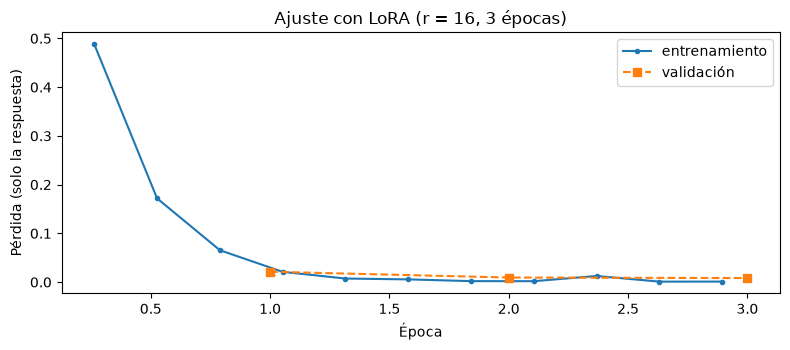

In [9]:
import math
EPOCAS, LOTE, ACUMULAR = 3, 4, 2
pasos_totales = math.ceil(len(ds_entrenamiento) / (LOTE * ACUMULAR)) * EPOCAS
pasos_calentamiento = max(1, round(0.05 * pasos_totales))      # 5 % de calentamiento (warmup)
args = TrainingArguments(output_dir=os.path.join(DIR_MODELOS, "lora_tickets"), num_train_epochs=EPOCAS, learning_rate=2e-4,
                         per_device_train_batch_size=LOTE, gradient_accumulation_steps=ACUMULAR, per_device_eval_batch_size=4,
                         warmup_steps=pasos_calentamiento, lr_scheduler_type="cosine", logging_steps=5, eval_strategy="epoch",
                         save_strategy="no", bf16=BF16, fp16=FP16, gradient_checkpointing=True, remove_unused_columns=False,
                         report_to="none", seed=SEED)
modelo.enable_input_require_grads()        # necesario con gradient checkpointing y el modelo base congelado
trainer = Trainer(model=modelo, args=args, train_dataset=ds_entrenamiento, eval_dataset=ds_validacion, data_collator=juntar)
if GPU:
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
seg_lora = time.time() - t0
modelo.eval()
modelo.config.use_cache = True
print(f"Entrenamiento: {seg_lora:.0f} s" + (f" · memoria máxima de GPU: {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB" if GPU else ""))

hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(8, 3.6))
perdida = hist.dropna(subset=["loss"])
ax.plot(perdida["epoch"], perdida["loss"], "o-", ms=3, label="entrenamiento")
if "eval_loss" in hist:
    val = hist.dropna(subset=["eval_loss"])
    ax.plot(val["epoch"], val["eval_loss"], "s--", label="validación")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (solo la respuesta)")
ax.set_title("Ajuste con LoRA (r = 16, 3 épocas)")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
ruta_adaptador = os.path.join(DIR_MODELOS, "lora_tickets_adaptador")
modelo.save_pretrained(ruta_adaptador)
tam = sum(os.path.getsize(os.path.join(ruta_adaptador, f)) for f in os.listdir(ruta_adaptador)) / 1024**2
print(f"Adaptador guardado en {ruta_adaptador}: {tam:.0f} MB (no se sube al repositorio)")

Adaptador guardado en modelos\C3\lora_tickets_adaptador: 34 MB (no se sube al repositorio)


## 4. Resultados
El modelo ajustado recibe **solo el *prompt* corto** y se mide con las mismas métricas, sobre la misma prueba escrita aparte.

In [11]:
resp_lora, ac_lora = evaluar(modelo, PROMPT_CORTO, "Qwen 0.5B + LoRA (r=16, 3 épocas) · prompt corto")

{'Configuración': 'Qwen 0.5B + LoRA (r=16, 3 épocas) · prompt corto', 'JSON válido': np.float64(1.0), 'nombre': np.float64(0.96), 'id_alumno': np.float64(0.84), 'area': np.float64(0.88), 'asunto': np.float64(0.96), 'urgente': np.float64(1.0), 'Promedio': np.float64(0.928), 'Tokens de entrada': np.float64(71.84), 'Segundos': 8.363}


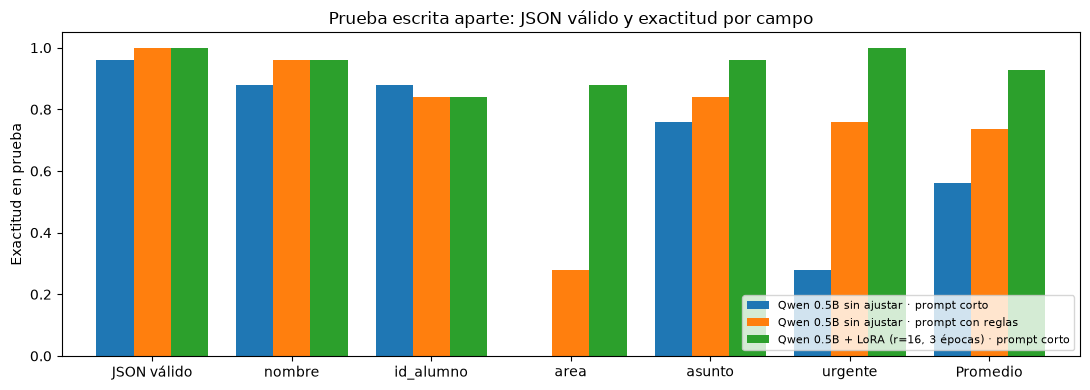

In [12]:
tabla_graf = pd.DataFrame(filas_resultados).set_index("Configuración")[["JSON válido", *CAMPOS, "Promedio"]]
ax = tabla_graf.T.plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Exactitud en prueba")
ax.set_title("Prueba escrita aparte: JSON válido y exactitud por campo")
ax.legend(fontsize=8, loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
resultados = pd.DataFrame(filas_resultados).set_index("Configuración")
resultados = resultados.astype(float).round(3)
resultados

,JSON válido,nombre,id_alumno,area,asunto,urgente,Promedio,Tokens de entrada,Segundos
Configuración,,,,,,,,,
Qwen 0.5B sin ajustar · prompt corto,0.96,0.88,0.88,0.00,0.76,0.28,0.560,71.84,7.332
Qwen 0.5B sin ajustar · prompt con reglas,1.00,0.96,0.84,0.28,0.84,0.76,0.736,407.84,4.380
"Qwen 0.5B + LoRA (r=16, 3 épocas) · prompt corto",1.00,0.96,0.84,0.88,0.96,1.00,0.928,71.84,8.363


## 5. Conclusión
### 5.1 Errores del modelo ajustado

In [14]:
mostrar_errores(resp_lora, ac_lora, maximo=10)
fallos_campo = pd.DataFrame(ac_lora).eq(False).sum().rename("Errores por campo (LoRA)")
fallos_campo.to_frame().T

Mensajes con algún campo incorrecto: 7 de 25

[9] falló: ['id_alumno']
  mensaje: Nunca recibo el codigo para entrar al portal. Atte. Sebastián Ibarra, A3318
  verdad:  {"nombre": "Sebastián Ibarra", "id_alumno": "A3318", "area": "sistemas", "asunto": "código de verificación", "urgente": false}
  modelo:  {"nombre": "Sebastián Ibarra", "id_alumno": null, "area": "sistemas", "asunto": "código de entrada a portal", "urgente": false}

[11] falló: ['area']
  mensaje: Buen día, Leonardo Cervantes, A0927. se me empalman Redes y Bases de Datos los martes
  verdad:  {"nombre": "Leonardo Cervantes", "id_alumno": "A0927", "area": "escolares", "asunto": "choque de horario", "urgente": false}
  modelo:  {"nombre": "Leonardo Cervantes", "id_alumno": "A0927", "area": "sistemas", "asunto": "empalma de redes y bases de datos", "urgente": false}

[15] falló: ['area']
  mensaje: hola me quiero salir de calculo, me llamo Gael Fuentes y mi matricula es A4401
  verdad:  {"nombre": "Gael Fuentes", "id_alumn

,nombre,id_alumno,area,asunto,urgente
Errores por campo (LoRA),1,4,3,1,0


### 5.2 ¿Qué olvidó el modelo?
`disable_adapter()` regresa al modelo original sin borrar nada. Comparamos el **mismo modelo con y sin adaptador** en peticiones que **no son su tarea**: una pregunta general, una instrucción creativa y un mensaje a la mesa de ayuda que no es un problema (con el *prompt* de la tarea).

In [15]:
peticiones = {
    "Pregunta general": [{"role": "user", "content": "En una frase: ¿qué es una red neuronal?"}],
    "Instrucción creativa": [{"role": "user", "content": "Escribe un haiku sobre los exámenes finales."}],
    "Mensaje que no es un problema (con el prompt de la tarea)": [
        {"role": "system", "content": PROMPT_CORTO},
        {"role": "user", "content": "Muchas gracias por resolver lo de mi beca tan rápido, que tengan buen fin de semana."}],
}
con, _ = generar_lote(modelo, list(peticiones.values()), max_new_tokens=70)
with modelo.disable_adapter():
    sin, _ = generar_lote(modelo, list(peticiones.values()), max_new_tokens=70)
for nombre_p, c, s in zip(peticiones, con, sin):
    print(f"--- {nombre_p}\n  SIN adaptador: {s}\n  CON adaptador: {c}\n")

--- Pregunta general
  SIN adaptador: Una red neuronal es un tipo de sistema computacional que se basa en la estructura y funcionamiento del cerebro humano. Estos sistemas neuronales son capaces de procesar información lógica y visualmente, lo cual los hace extremadamente útiles para el aprendizaje automático y la inteligencia artificial.

Las redes neuronales
  CON adaptador: una red neuronal es un sistema de neuronas que se conectan entre sí para procesar y interpretar información lógica. estas neuronas pueden ser capaces de aprender y mejorar su capacidad para reconocer patrones en datos, lo cual es fundamental para la inteligencia artificial.

--- Instrucción creativa
  SIN adaptador: Exámenes finales,
Nuevas preguntas y desafíos,
Aprendizaje constante.
  CON adaptador: sorprendido por el examen,
esperando la respuesta,
feliz con el éxito.

--- Mensaje que no es un problema (con el prompt de la tarea)
  SIN adaptador: ¡Gracias por tu comprensión! Estoy aquí para ayudarte con cualqu

### 5.3 Conclusión
**LoRA sí funcionó, y mucho.** Con el mismo *prompt* corto, el modelo sin ajustar sacó 56 % de promedio por campo y el ajustado **92.8 %**. Le ganó incluso al *prompt* con reglas (73.6 %), que además gasta 408 tokens de entrada contra 72. El entrenamiento solo tardó 26 s y movió el 1.75 % de los parámetros (8.8 M). Sin ajustar, el modelo casi nunca usaba las 4 áreas permitidas (0 % con el *prompt* corto, 28 % con reglas): ponía cosas como "Moodle", "Colegiatura" o "Física". Además envolvía el JSON en texto y marcaba como urgente cualquier cosa, por ejemplo una clave de Moodle. Con LoRA, el JSON salió válido el 100 % de las veces, `area` acertó 88 % y **`urgente` 100 %**, que es el campo que más importa porque ahí no se puede fallar.

**Errores que le quedaron** (7 de 25 mensajes, casi todos en un solo campo):
1. **La matrícula cuando viene en un formato que no vio** (4 errores). En el entrenamiento casi siempre decía "matrícula A1234", así que cuando la matrícula venía sola al final del mensaje, como en «Atte. Sebastián Ibarra, A3318» o «soy Camila Treviño, A6127», puso `null`. Y con «A 5 9 7 1» inventó "B5J1" y además cambió el nombre a "Julía Arce". En los datos hacían falta más formas de escribir la matrícula.
2. **El área cuando el problema está dicho con otras palabras** (3 errores). «se me empalman Redes y Bases de Datos» lo mandó a *sistemas*, seguramente por "Redes" y "Bases de Datos", que suenan a computación. «me quiero salir de cálculo» también se fue a *sistemas* porque nunca vio "salir" como "dar de baja". Y «me suspendieron la cuenta de correo» se fue a *finanzas*, quizá por "cuenta" o "suspendieron". Es el mismo problema que con BETO en la práctica: aprende las frases de sus plantillas, no la intención.

**Qué olvidó:** con la pregunta general y con el haiku contesta casi igual con y sin adaptador, así que no perdió lo que ya sabía hacer (aunque con el adaptador escribe todo en minúsculas, como muchos mensajes del entrenamiento). Pero cuando le doy el *prompt* de la tarea y un mensaje que no es un problema («muchas gracias por resolver lo de mi beca»), sin adaptador responde normal y con adaptador **inventa un ticket** con un nombre falso ("Juan José") y asunto "solicitud de beca". O sea, se volvió un especialista: con su *prompt*, todo lo convierte en ticket, aunque no lo sea. En un sistema real habría que poner antes un filtro que decida si el mensaje de verdad es una solicitud.